# Motus Xponential - UJ Hackathon - Sample Notebook

**NOTE:** Please paste your `requirements.txt` file in the cell below this one, this ensures your notebook runs in the same environment as when you developed it.


> Feel free to modify this notebook anythow, but please make sure your model outputs four probabilites for each entry, namely: `p_quote, p_prospect, p_inspection,` and `p_accepted`. See `save_submission` function below.

# 0. Paste `requirements.txt` here 

anyio==4.14.1
argon2-cffi==25.1.0
argon2-cffi-bindings==25.1.0
arrow==1.4.0
asttokens==3.0.1
async-lru==2.3.0
attrs==26.1.0
babel==2.18.0
beautifulsoup4==4.15.0
bleach==6.4.0
certifi==2026.6.17
cffi==2.0.0
charset-normalizer==3.4.7
colorama==0.4.6
comm==0.2.3
contourpy==1.3.3
cycler==0.12.1
debugpy==1.8.21
decorator==5.3.1
defusedxml==0.7.1
executing==2.2.1
fastjsonschema==2.21.2
fonttools==4.63.0
fqdn==1.5.1
h11==0.16.0
httpcore==1.0.9
httpx==0.28.1
idna==3.18
ipykernel==7.3.0
ipython==9.15.0
ipython_pygments_lexers==1.1.1
ipywidgets==8.1.8
isoduration==20.11.0
jedi==0.20.0
Jinja2==3.1.6
joblib==1.5.3
json5==0.15.0
jsonpointer==3.1.1
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter==1.1.1
jupyter-console==6.6.3
jupyter-events==0.12.1
jupyter-lsp==2.3.1
jupyter_builder==1.0.2
jupyter_client==8.9.1
jupyter_core==5.9.1
jupyter_server==2.20.0
jupyter_server_terminals==0.5.4
jupyterlab==4.6.0
jupyterlab_pygments==0.3.0
jupyterlab_server==2.28.0
jupyterlab_widgets==3.0.16
kiwisolver==1.5.0
lark==1.3.1
MarkupSafe==3.0.3
matplotlib==3.11.0
matplotlib-inline==0.2.2
mistune==3.3.2
narwhals==2.22.1
nbclient==0.11.0
nbconvert==7.17.1
nbformat==5.10.4
nest-asyncio2==1.7.2
notebook==7.6.0
notebook_shim==0.2.4
numpy==2.5.0
packaging==26.2
pandas==3.0.3
pandocfilters==1.5.1
parso==0.8.7
pillow==12.2.0
platformdirs==4.10.0
prometheus_client==0.25.0
prompt_toolkit==3.0.52
psutil==7.2.2
pure_eval==0.2.3
pycparser==3.0
Pygments==2.20.0
pyparsing==3.3.2
python-dateutil==2.9.0.post0
python-json-logger==4.1.0
pywinpty==3.0.5
PyYAML==6.0.3
pyzmq==27.1.0
referencing==0.37.0
requests==2.34.2
rfc3339-validator==0.1.4
rfc3986-validator==0.1.1
rfc3987-syntax==1.1.0
rpds-py==2026.5.1
scikit-learn==1.9.0
scipy==1.18.0
Send2Trash==2.1.0
six==1.17.0
soupsieve==2.8.4
stack-data==0.6.3
terminado==0.18.1
threadpoolctl==3.6.0
tinycss2==1.5.1
tornado==6.5.7
traitlets==5.15.1
typing_extensions==4.15.0
tzdata==2026.2
uri-template==1.3.0
urllib3==2.7.0
wcwidth==0.8.1
webcolors==25.10.0
webencodings==0.5.1
websocket-client==1.9.0
widgetsnbextension==4.0.15


# 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 2. Data Loading

In [2]:
# stream the data directly from the site
# df_train = pd.read_csv("https://motushackathon.co.za/api/download/train")
# df_test = pd.read_csv("https://motushackathon.co.za/api/download/test")
# deal_call = pd.read_csv("https://motushackathon.co.za/api/download/deal-call")

# these links ar not working so we use the downloaded files in the project
df_train = pd.read_csv("data/raw/train.csv")
df_test = pd.read_csv("data/raw/test.csv")
deal_call = pd.read_csv("data/raw/deal_call.csv")

# 2.1 Lock in the raw test deal_ref (fix)

In [3]:
test_deal_refs = df_test["deal_ref"].astype(str).copy()

print("deal_ref dtype:", df_test["deal_ref"].dtype)
print("Sample deal_ref values:", test_deal_refs.head(5).tolist())

deal_ref dtype: object
Sample deal_ref values: ['GW00048828', 'GW00476614', 'GW00525146', 'GW00526094', 'GW00526169']


# 2.1 Initial Data Checks

In [4]:
print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)
print("Deal Call shape:", deal_call.shape)

Train shape: (33888, 35)
Test shape: (8263, 26)
Deal Call shape: (38983, 7)


# 2.2 Column structure

In [5]:
print("TRAIN COLUMNS:\n", df_train.columns.tolist())
print("\nTEST COLUMNS:\n", df_test.columns.tolist())
print("\nDEAL CALL COLUMNS:\n", deal_call.columns.tolist())

TRAIN COLUMNS:
 ['date_created', 'deal_ref', 'deal_status', 'deal type', 'year', 'vehicle', 'mileage', 'colour', 'condition', 'service history', 'location', 'urgency', 'list price', 'count', 'quote', 'quote_date', 'prospect', 'prospect_date', 'inspection', 'inspection_date', 'accepted', 'accepted_date', 'client_id', 'referer', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_content', 'utm_term', 'date', 'week', 'ga name final', 'ga medium final', 'ga channel final', 'month']

TEST COLUMNS:
 ['deal_ref', 'deal type', 'year', 'vehicle', 'mileage', 'colour', 'condition', 'service history', 'location', 'urgency', 'list price', 'count', 'client_id', 'referer', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_content', 'utm_term', 'date', 'week', 'ga name final', 'ga medium final', 'ga channel final', 'month', 'date_created']

DEAL CALL COLUMNS:
 ['date_created', 'deal_ref', 'comments', 'call_back_date', 'curator_id', 'call_back_type', 'deal_id']


# 2.3 Check missing values

In [6]:
missing_train = df_train.isnull().sum().sort_values(ascending=False)
missing_test = df_test.isnull().sum().sort_values(ascending=False)

print("TOP TRAIN MISSING VALUES:\n", missing_train.head(15))
print("\nTOP TEST MISSING VALUES:\n", missing_test.head(15))

TOP TRAIN MISSING VALUES:
 utm_content        31736
utm_term           31710
accepted_date      31456
inspection_date    29849
utm_campaign       28723
utm_medium         28670
utm_source         28662
prospect_date      25518
quote_date         14841
referer             4761
client_id            492
urgency              151
ga name final         27
ga medium final        4
condition              3
dtype: int64

TOP TEST MISSING VALUES:
 utm_term            7401
utm_content         7383
utm_campaign        4043
utm_medium          4023
utm_source          4020
referer             1195
urgency               77
client_id             61
colour                 4
month                  0
ga channel final       0
ga medium final        0
ga name final          0
week                   0
date                   0
dtype: int64


# 2.4 Validate target structure

In [7]:
target_cols = ["quote", "prospect", "inspection", "accepted"]

print(df_train[target_cols].mean())
print("\nTarget Correlation:\n")
print(df_train[target_cols].corr())

quote         0.998229
prospect      0.684077
inspection    0.431038
accepted      0.290811
dtype: float64

Target Correlation:

               quote  prospect  inspection  accepted
quote       1.000000 -0.022581   -0.038465 -0.051857
prospect   -0.022581  1.000000    0.582270  0.429024
inspection -0.038465  0.582270    1.000000  0.735713
accepted   -0.051857  0.429024    0.735713  1.000000


# 3. Data Exploration & Cleaning

# 3.1 Explore numerical features

In [8]:
numerical_cols = df_train.select_dtypes(include=["number"]).columns

print("Numerical Columns:")
print(numerical_cols.tolist())

print("\nSummary Statistics:")
display(df_train[numerical_cols].describe().T)

Numerical Columns:
['year', 'mileage', 'list price', 'count', 'quote', 'prospect', 'inspection', 'accepted']

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
year,33888.0,2018.757790,3.368058,1990.0,2017.0,2019.0,2021.0,2025.0
mileage,33888.0,79936.056333,43184.647406,0.0,46300.0,77800.0,110000.0,484000.0
list price,33888.0,269474.321884,147550.462202,999.0,164900.0,229900.0,334900.0,1999900.0
count,33888.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
quote,33888.0,0.998229,0.042041,0.0,1.0,1.0,1.0,1.0
prospect,33888.0,0.684077,0.464889,0.0,0.0,1.0,1.0,1.0
inspection,33888.0,0.431038,0.495229,0.0,0.0,0.0,1.0,1.0
accepted,33888.0,0.290811,0.454143,0.0,0.0,0.0,1.0,1.0


# 3.2 Categorial variables

In [9]:
categorical_cols = df_train.select_dtypes(include=["object", "string"]).columns

print("Categorical Columns:")
print(categorical_cols.tolist())

print("\nNumber of unique values:\n")

for col in categorical_cols:
    print(f"{col}: {df_train[col].nunique()} unique values")

Categorical Columns:
['date_created', 'deal_ref', 'deal_status', 'deal type', 'vehicle', 'colour', 'condition', 'service history', 'location', 'urgency', 'quote_date', 'prospect_date', 'inspection_date', 'accepted_date', 'client_id', 'referer', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_content', 'utm_term', 'date', 'week', 'ga name final', 'ga medium final', 'ga channel final', 'month']

Number of unique values:

date_created: 33825 unique values
deal_ref: 19015 unique values
deal_status: 4 unique values
deal type: 6 unique values
vehicle: 2960 unique values
colour: 15 unique values
condition: 4 unique values
service history: 5 unique values
location: 162 unique values
urgency: 4 unique values
quote_date: 19027 unique values
prospect_date: 8365 unique values
inspection_date: 4039 unique values
accepted_date: 2431 unique values
client_id: 14745 unique values
referer: 92 unique values
utm_source: 11 unique values
utm_medium: 21 unique values
utm_campaign: 51 unique values
utm_cont

# 3.3 Inspect target class distributions

In [10]:
target_cols = ["quote", "prospect", "inspection", "accepted"]

for target in target_cols:
    print(f"\n{target.upper()} Distribution")
    print(df_train[target].value_counts())
    print("-" * 40)


QUOTE Distribution
quote
1    33828
0       60
Name: count, dtype: int64
----------------------------------------

PROSPECT Distribution
prospect
1    23182
0    10706
Name: count, dtype: int64
----------------------------------------

INSPECTION Distribution
inspection
0    19281
1    14607
Name: count, dtype: int64
----------------------------------------

ACCEPTED Distribution
accepted
0    24033
1     9855
Name: count, dtype: int64
----------------------------------------


# 3.4 Visualize numerical distributions

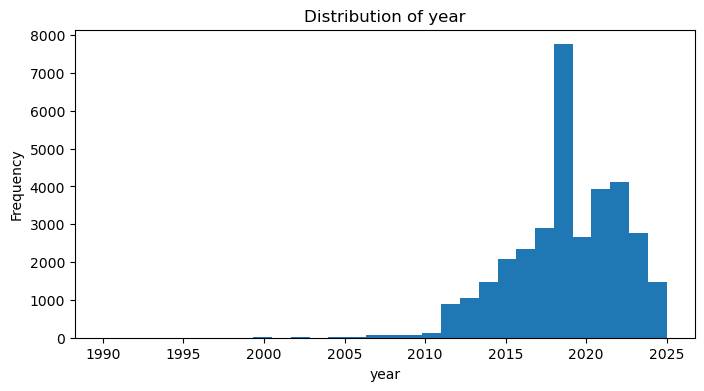

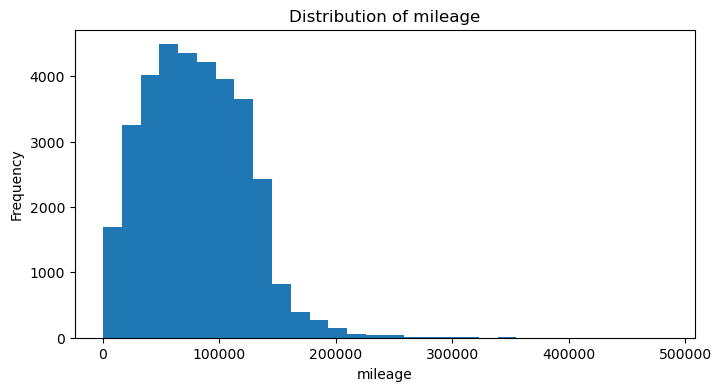

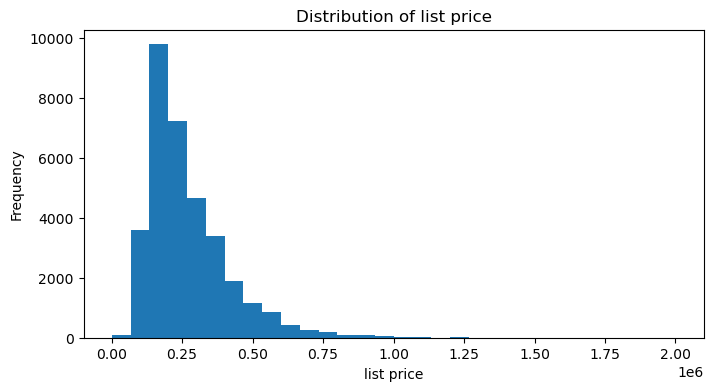

In [11]:
numerical_cols = ["year", "mileage", "list price"]

for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(df_train[col].dropna(), bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# 3.5 Detect outliers

In [ ]:
numerical_cols = ["year", "mileage", "list price"]

for col in numerical_cols:
    plt.figure(figsize=(8, 2.5))
    plt.boxplot(
        df_train[col].dropna(),
        vert=False
    )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

TypeError: boxplot() got an unexpected keyword argument 'orientation'

<Figure size 800x250 with 0 Axes>

# 3.6 Explore relationships between variables

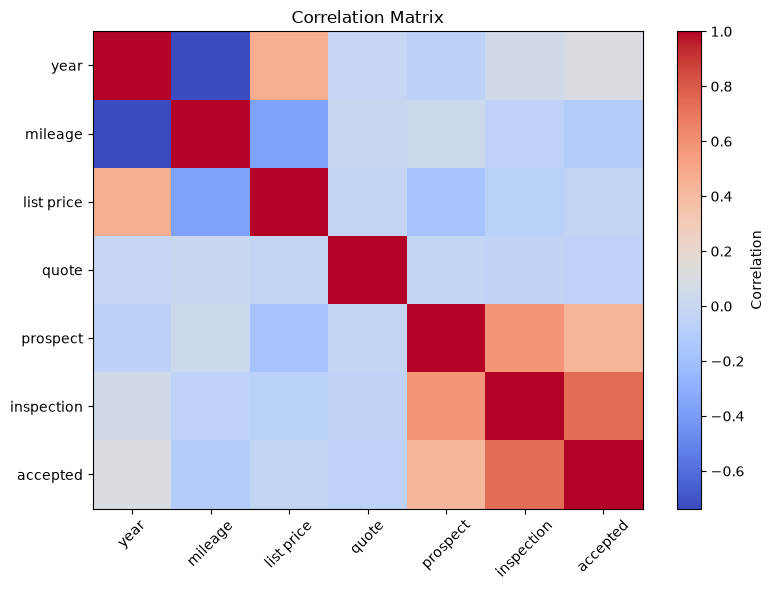

                year   mileage  list price     quote  prospect  inspection  \
year        1.000000 -0.736552    0.472994 -0.010740 -0.063063    0.049873   
mileage    -0.736552  1.000000   -0.372648  0.003300  0.025507   -0.053582   
list price  0.472994 -0.372648    1.000000 -0.019198 -0.180046   -0.078432   
quote      -0.010740  0.003300   -0.019198  1.000000 -0.022581   -0.038465   
prospect   -0.063063  0.025507   -0.180046 -0.022581  1.000000    0.582270   
inspection  0.049873 -0.053582   -0.078432 -0.038465  0.582270    1.000000   
accepted    0.105299 -0.110589   -0.030751 -0.051857  0.429024    0.735713   

            accepted  
year        0.105299  
mileage    -0.110589  
list price -0.030751  
quote      -0.051857  
prospect    0.429024  
inspection  0.735713  
accepted    1.000000  


In [ ]:
numerical_cols = [
    "year",
    "mileage",
    "list price",
    "quote",
    "prospect",
    "inspection",
    "accepted"
]

corr_matrix = df_train[numerical_cols].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print(corr_matrix)

# 3.7 Explore time-based features

In [ ]:
date_cols = ["date_created", "date", "quote_date", "prospect_date", "inspection_date", "accepted_date"]

for col in date_cols:
    print(f"\n{col}")
    print(df_train[col].head(5))
    print("Missing:", df_train[col].isnull().sum())


date_created
0    2024-10-07 11:36:33
1    2024-10-07 12:44:31
2    2024-10-07 13:13:13
3    2024-10-07 13:25:04
4    2024-10-07 13:34:24
Name: date_created, dtype: str
Missing: 0

date
0    2024-07-10
1    2024-07-10
2    2024-07-10
3    2024-07-10
4    2024-07-10
Name: date, dtype: str
Missing: 0

quote_date
0    2024-10-07 11:36:33
1    2024-10-07 12:44:31
2    2024-10-07 13:13:13
3    2024-10-07 13:25:04
4                    NaN
Name: quote_date, dtype: str
Missing: 14841

prospect_date
0                    NaN
1                    NaN
2                    NaN
3                    NaN
4    2024-10-07 13:34:24
Name: prospect_date, dtype: str
Missing: 25518

inspection_date
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: inspection_date, dtype: str
Missing: 29849

accepted_date
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: accepted_date, dtype: str
Missing: 31456


# 3.8 Missing Value Summary

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df_train.isnull().sum(),
    "Missing (%)": (df_train.isnull().mean() * 100).round(2),
    "Data Type": df_train.dtypes.astype(str)
})

missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing (%)", ascending=False)
)

missing_summary

,Missing Count,Missing (%),Data Type
utm_content,31736,93.65,str
utm_term,31710,93.57,str
accepted_date,31456,92.82,str
inspection_date,29849,88.08,str
utm_campaign,28723,84.76,str
utm_medium,28670,84.60,str
utm_source,28662,84.58,str
prospect_date,25518,75.30,str
quote_date,14841,43.79,str
referer,4761,14.05,str


# 3.9 Convert Date Columns to Datetime

In [ ]:
date_columns = [
    "date_created",
    "date",
    "quote_date",
    "prospect_date",
    "inspection_date",
    "accepted_date"
]

for col in date_columns:
    df_train[col] = pd.to_datetime(df_train[col], errors="coerce")

# Apply the same conversion to test data 
test_date_columns = ["date_created", "date"]

for col in test_date_columns:
    df_test[col] = pd.to_datetime(df_test[col], errors="coerce")

print(df_train[date_columns].dtypes)
print("\n")
print(df_test[test_date_columns].dtypes)

date_created       datetime64[us]
date               datetime64[us]
quote_date         datetime64[us]
prospect_date      datetime64[us]
inspection_date    datetime64[us]
accepted_date      datetime64[us]
dtype: object


date_created    datetime64[us]
date            datetime64[us]
dtype: object


# 3.10 Inspect Constant & Leakage Columns

In [ ]:
print("Constant Columns:\n")

constant_cols = []

for col in df_train.columns:
    unique_count = df_train[col].nunique(dropna=False)
    if unique_count == 1:
        constant_cols.append(col)

print(constant_cols)

print("\nPotential Leakage Columns:")

leakage_cols = [
    "deal_status",
    "quote_date",
    "prospect_date",
    "inspection_date",
    "accepted_date"
]

for col in leakage_cols:
    print(f"\n{col}")
    print(df_train[col].value_counts(dropna=False).head())

Constant Columns:

['count']

Potential Leakage Columns:

deal_status
deal_status
Quote         19047
Prospect       8370
Inspection     4039
Accepted       2432
Name: count, dtype: int64

quote_date
quote_date
NaT                    14841
2024-11-02 08:24:09        2
2024-11-26 08:58:55        2
2025-01-14 10:50:18        2
2025-02-04 08:53:56        2
Name: count, dtype: int64

prospect_date
prospect_date
NaT                    25518
2024-11-15 15:44:16        2
2025-01-10 16:00:07        2
2025-01-20 14:56:14        2
2025-03-24 14:32:07        2
Name: count, dtype: int64

inspection_date
inspection_date
NaT                    29849
2024-10-07 14:59:47        1
2024-10-09 08:55:45        1
2024-10-09 10:03:08        1
2024-10-09 10:10:25        1
Name: count, dtype: int64

accepted_date
accepted_date
NaT                    31456
2025-03-25 15:16:24        2
2024-10-10 13:04:30        1
2024-10-10 13:05:25        1
2024-10-10 13:43:21        1
Name: count, dtype: int64


# 3.11 Check for Duplicate Records

In [ ]:
print("Duplicate rows in train:", df_train.duplicated().sum())
print("Duplicate rows in test:", df_test.duplicated().sum())
print("Duplicate rows in deal_call:", deal_call.duplicated().sum())

print("\nDuplicate deal_ref values")

print("Train:", df_train["deal_ref"].duplicated().sum())
print("Test :", df_test["deal_ref"].duplicated().sum())
print("Deal Call:", deal_call["deal_ref"].duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in test: 0
Duplicate rows in deal_call: 122

Duplicate deal_ref values
Train: 14817
Test : 6236
Deal Call: 23416


# 3.12 Apply Initial Missing Value Handling

In [ ]:
# Fill categorical missing values with "Unknown"
categorical_fill = [
    "utm_source",
    "utm_medium",
    "utm_campaign",
    "utm_content",
    "utm_term",
    "referer",
    "client_id",
    "urgency",
    "condition",
    "colour",
    "ga name final",
    "ga medium final"
]

for col in categorical_fill:
    if col in df_train.columns:
        df_train[col] = df_train[col].fillna("Unknown")
    if col in df_test.columns:
        df_test[col] = df_test[col].fillna("Unknown")

# Check remaining missing values
remaining_missing = (
    df_train.isnull()
    .sum()
    .sort_values(ascending=False)
)

print(remaining_missing[remaining_missing > 0])

accepted_date      31456
inspection_date    29849
prospect_date      25518
date               20446
quote_date         14841
dtype: int64


# 4. Data Preprocessing & Transformation

# 4.1 Create working copies of the datasets

In [ ]:
train_df = df_train.copy()
test_df = df_test.copy()
deal_call_df = deal_call.copy()

print("Working copies created successfully.")

Working copies created successfully.


# 4.2 Remove constant and data leakage columns

In [ ]:
train_drop_cols = [
    "count",
    "deal_status",
    "quote_date",
    "prospect_date",
    "inspection_date",
    "accepted_date"
]

test_drop_cols = [
    "count"
]

# Drop columns
train_df = train_df.drop(columns=train_drop_cols)
test_df = test_df.drop(columns=test_drop_cols)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nRemaining columns in train:")
print(train_df.columns.tolist())

Train shape: (33888, 29)
Test shape: (14524, 25)

Remaining columns in train:
['date_created', 'deal_ref', 'deal type', 'year', 'vehicle', 'mileage', 'colour', 'condition', 'service history', 'location', 'urgency', 'list price', 'quote', 'prospect', 'inspection', 'accepted', 'client_id', 'referer', 'utm_source', 'utm_medium', 'utm_campaign', 'utm_content', 'utm_term', 'date', 'week', 'ga name final', 'ga medium final', 'ga channel final', 'month']


# 4.3 Handle missing values

In [ ]:
# Fill categorical missing values

mode_columns = [
    "colour",
    "condition",
    "urgency"
]

unknown_columns = [
    "client_id",
    "referer",
    "utm_source",
    "utm_medium",
    "utm_campaign",
    "utm_content",
    "utm_term",
    "ga name final",
    "ga medium final"
]

# Fill with mode
for col in mode_columns:
    mode_value = train_df[col].mode()[0]
    train_df[col] = train_df[col].fillna(mode_value)
    test_df[col] = test_df[col].fillna(mode_value)

# Fill with "Unknown"
for col in unknown_columns:
    train_df[col] = train_df[col].fillna("Unknown")
    test_df[col] = test_df[col].fillna("Unknown")

print("Remaining missing values (Top 15):")
print(train_df.isnull().sum().sort_values(ascending=False).head(15))

Remaining missing values (Top 15):
date                20446
date_created            0
accepted                0
ga channel final        0
ga medium final         0
ga name final           0
week                    0
utm_term                0
utm_content             0
utm_campaign            0
utm_medium              0
utm_source              0
referer                 0
client_id               0
inspection              0
dtype: int64


# 4.4 Engineer datetime features

In [ ]:
# Date columns to engineer
date_columns = ["date_created", "date"]

for col in date_columns:
    train_df[f"{col}_year"] = train_df[col].dt.year
    train_df[f"{col}_month"] = train_df[col].dt.month
    train_df[f"{col}_day"] = train_df[col].dt.day
    train_df[f"{col}_dayofweek"] = train_df[col].dt.dayofweek

    test_df[f"{col}_year"] = test_df[col].dt.year
    test_df[f"{col}_month"] = test_df[col].dt.month
    test_df[f"{col}_day"] = test_df[col].dt.day
    test_df[f"{col}_dayofweek"] = test_df[col].dt.dayofweek

print(train_df.filter(regex="date").head())

         date_created       date  date_created_year  date_created_month  \
0 2024-10-07 11:36:33 2024-07-10               2024                  10   
1 2024-10-07 12:44:31 2024-07-10               2024                  10   
2 2024-10-07 13:13:13 2024-07-10               2024                  10   
3 2024-10-07 13:25:04 2024-07-10               2024                  10   
4 2024-10-07 13:34:24 2024-07-10               2024                  10   

   date_created_day  date_created_dayofweek  date_year  date_month  date_day  \
0                 7                       0     2024.0         7.0      10.0   
1                 7                       0     2024.0         7.0      10.0   
2                 7                       0     2024.0         7.0      10.0   
3                 7                       0     2024.0         7.0      10.0   
4                 7                       0     2024.0         7.0      10.0   

   date_dayofweek  
0             2.0  
1             2.0  
2       

In [ ]:
# Extract time-based features from date_created

train_df["created_hour"] = train_df["date_created"].dt.hour
train_df["created_minute"] = train_df["date_created"].dt.minute

test_df["created_hour"] = test_df["date_created"].dt.hour
test_df["created_minute"] = test_df["date_created"].dt.minute

print(
    train_df[
        [
            "date_created",
            "created_hour",
            "created_minute"
        ]
    ].head()
)

         date_created  created_hour  created_minute
0 2024-10-07 11:36:33            11              36
1 2024-10-07 12:44:31            12              44
2 2024-10-07 13:13:13            13              13
3 2024-10-07 13:25:04            13              25
4 2024-10-07 13:34:24            13              34


# 4.5 Engineer vehicle-related features

In [ ]:
CURRENT_YEAR = 2026

train_df["vehicle_age"] = CURRENT_YEAR - train_df["year"]
test_df["vehicle_age"] = CURRENT_YEAR - test_df["year"]

train_df[["year", "vehicle_age"]].head()

,year,vehicle_age
0,2020,6
1,2017,9
2,2016,10
3,2017,9
4,2017,9


## 4.5.1 Extract vehicle text features (make, engine size, drivetrain)

`vehicle` is currently only label-encoded as a single high-cardinality ID (basically a near-unique string per row), which gives a tree model almost nothing to generalize from. Parsing out the actual make, engine size, and drivetrain/turbo flags turns it into real, reusable signal (bonus challenge: *text feature extraction*).

In [ ]:
import re

def extract_vehicle_text_features(df):
    vehicle_str = df["vehicle"].astype(str)
    df["vehicle_make"] = vehicle_str.str.split().str[0].str.upper()
    engine_match = vehicle_str.str.extract(r"(\d\.\d)")
    df["vehicle_engine_size"] = pd.to_numeric(engine_match[0], errors="coerce")
    df["vehicle_is_awd_4wd"] = vehicle_str.str.contains(r"\b(?:AWD|4WD|4X4)\b", case=False, regex=True).astype(int)
    df["vehicle_is_turbo"] = vehicle_str.str.contains(r"TURBO|\bT\b", case=False, regex=True).astype(int)
    return df

train_df = extract_vehicle_text_features(train_df)
test_df = extract_vehicle_text_features(test_df)

# bucket rare makes so one-hot encoding downstream stays manageable
make_counts = train_df["vehicle_make"].value_counts()
common_makes = make_counts[make_counts >= 30].index
train_df["vehicle_make"] = train_df["vehicle_make"].where(train_df["vehicle_make"].isin(common_makes), "Other")
test_df["vehicle_make"] = test_df["vehicle_make"].where(test_df["vehicle_make"].isin(common_makes), "Other")

engine_median = train_df["vehicle_engine_size"].median()
train_df["vehicle_engine_size"] = train_df["vehicle_engine_size"].fillna(engine_median)
test_df["vehicle_engine_size"] = test_df["vehicle_engine_size"].fillna(engine_median)

print("Top vehicle makes:")
print(train_df["vehicle_make"].value_counts().head(10))
print("\nEngine size found for (%):", round(100 * train_df["vehicle_engine_size"].ne(engine_median).mean(), 1))


## 4.5.2 Engineer repeat-consumer features (client_id history)

Right now `client_id` is only label-encoded as a raw ID, which is another near-unique identifier a tree model can't generalize from. What actually matters commercially is *history*: has this consumer enquired before, how recently, and did their last enquiry convert? (bonus challenge: *repeat consumer modelling*).

This is built carefully to avoid leakage: for every enquiry we only look at *strictly earlier* enquiries (by `date_created`) from the same client, and we only ever use a KNOWN outcome (from `train_df`) when computing a client's prior acceptance rate - a prior test-set enquiry with an unknown label never contributes to it.

In [ ]:
combined_client = pd.concat([
    train_df[["client_id", "date_created"]].assign(_split="train", _idx=train_df.index),
    test_df[["client_id", "date_created"]].assign(_split="test", _idx=test_df.index),
], ignore_index=True)

combined_client["_accepted"] = np.nan
combined_client.loc[combined_client["_split"] == "train", "_accepted"] = train_df["accepted"].values

combined_client = combined_client.sort_values("date_created").reset_index(drop=True)
known_client_mask = (combined_client["client_id"].astype(str) != "Unknown").to_numpy()

n = len(combined_client)
prior_count = np.zeros(n)
prior_accepted_sum = np.zeros(n)
prior_labeled_count = np.zeros(n)
days_since_last = np.full(n, -1.0)

seen_count, last_seen, accepted_sum, labeled_count = {}, {}, {}, {}

for i in range(n):
    if not known_client_mask[i]:
        continue
    cid = combined_client.at[i, "client_id"]
    ts = combined_client.at[i, "date_created"]

    prior_count[i] = seen_count.get(cid, 0)
    prior_accepted_sum[i] = accepted_sum.get(cid, 0.0)
    prior_labeled_count[i] = labeled_count.get(cid, 0)
    if cid in last_seen:
        days_since_last[i] = (ts - last_seen[cid]).total_seconds() / 86400

    # update history AFTER reading it, so a row never sees its own outcome
    seen_count[cid] = seen_count.get(cid, 0) + 1
    last_seen[cid] = ts
    outcome = combined_client.at[i, "_accepted"]
    if not np.isnan(outcome):
        accepted_sum[cid] = accepted_sum.get(cid, 0.0) + outcome
        labeled_count[cid] = labeled_count.get(cid, 0) + 1

global_accept_rate = train_df["accepted"].mean()

combined_client["prior_enquiry_count"] = prior_count
combined_client["days_since_last_enquiry"] = days_since_last
combined_client["prior_accept_rate"] = np.where(
    prior_labeled_count > 0, prior_accepted_sum / np.maximum(prior_labeled_count, 1), global_accept_rate
)
combined_client["has_prior_labeled_history"] = (prior_labeled_count > 0).astype(int)

# rows with no known client_id get neutral defaults, not accidental zeros
no_client = ~known_client_mask
combined_client.loc[no_client, "prior_enquiry_count"] = 0
combined_client.loc[no_client, "days_since_last_enquiry"] = -1
combined_client.loc[no_client, "prior_accept_rate"] = global_accept_rate
combined_client.loc[no_client, "has_prior_labeled_history"] = 0

repeat_feature_cols = ["prior_enquiry_count", "days_since_last_enquiry", "prior_accept_rate", "has_prior_labeled_history"]
train_feats = combined_client[combined_client["_split"] == "train"].set_index("_idx")
test_feats = combined_client[combined_client["_split"] == "test"].set_index("_idx")

for col in repeat_feature_cols:
    train_df[col] = train_feats[col]
    test_df[col] = test_feats[col]

print(train_df[["client_id"] + repeat_feature_cols].head(10))
print("\nShare of enquiries that are repeat clients:", round((train_df["prior_enquiry_count"] > 0).mean(), 4))


# 4.6 Engineer pricing and mileage features

In [ ]:
train_df["price_per_year"] = train_df["list price"] / (train_df["vehicle_age"] + 1)
test_df["price_per_year"] = test_df["list price"] / (test_df["vehicle_age"] + 1)

train_df[["list price", "vehicle_age", "price_per_year"]].head()

,list price,vehicle_age,price_per_year
0,589900,6,84271.428571
1,219900,9,21990.000000
2,162900,10,14809.090909
3,217900,9,21790.000000
4,217900,9,21790.000000


# 4.7 Engineer marketing features

In [ ]:
marketing_cols = [
    "referer",
    "utm_source",
    "utm_medium",
    "utm_campaign",
    "utm_content",
    "utm_term"
]

for col in marketing_cols:
    train_df[f"{col}_available"] = train_df[col].notna().astype(int)
    test_df[f"{col}_available"] = test_df[col].notna().astype(int)

train_df[[f"{col}_available" for col in marketing_cols]].head()

,referer_available,utm_source_available,utm_medium_available,utm_campaign_available,utm_content_available,utm_term_available
0,1,1,1,1,1,1
1,1,1,1,1,1,1
2,1,1,1,1,1,1
3,1,1,1,1,1,1
4,1,1,1,1,1,1


# 4.8 Process deal_call into useful features

## 4.8.1 Explore the dataset

In [ ]:
print("Shape:", deal_call.shape)

print("\nColumns:")
print(deal_call.columns.tolist())

print("\nMissing Values:")
print(deal_call.isnull().sum())

print("\nUnique deal_ref values:")
print(deal_call["deal_ref"].nunique())

print("\nCall Back Types:")
print(deal_call["call_back_type"].value_counts(dropna=False))

Shape: (38951, 7)

Columns:
['date_created', 'deal_ref', 'comments', 'call_back_date', 'curator_id', 'call_back_type', 'deal_id']

Missing Values:
date_created          0
deal_ref              0
comments           4271
call_back_date    12627
curator_id            0
call_back_type        0
deal_id               0
dtype: int64

Unique deal_ref values:
15535

Call Back Types:
call_back_type
1    26375
2     8306
0     4270
Name: count, dtype: int64


## 4.8.2 Aggregate call information

In [ ]:
deal_call_features = (
    deal_call
    .groupby("deal_ref")
    .agg(
        total_calls=("deal_id", "count"),
        unique_curators=("curator_id", "nunique"),
        has_comment=("comments", lambda x: x.notna().sum()),
        has_callback_date=("call_back_date", lambda x: x.notna().sum()),
        callback_type_0=("call_back_type", lambda x: (x == 0).sum()),
        callback_type_1=("call_back_type", lambda x: (x == 1).sum()),
        callback_type_2=("call_back_type", lambda x: (x == 2).sum()),
    )
    .reset_index()
)

deal_call_features.head()

,deal_ref,total_calls,unique_curators,has_comment,has_callback_date,callback_type_0,callback_type_1,callback_type_2
0,91183,1,1,1,0,0,0,1
1,110753,4,1,4,3,0,3,1
2,165377,4,3,3,3,1,3,0
3,185408,1,1,1,0,0,0,1
4,187333,3,1,3,3,0,3,0


## 4.8.3 Merge into train/test

In [ ]:
train_df = train_df.merge(
    deal_call_features,
    on="deal_ref",
    how="left"
)

test_df = test_df.merge(
    deal_call_features,
    on="deal_ref",
    how="left"
)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

Train shape: (33888, 54)
Test shape : (14524, 50)


## 4.8.4 Validate merged features

In [ ]:
call_features = [
    "total_calls",
    "unique_curators",
    "has_comment",
    "has_callback_date",
    "callback_type_0",
    "callback_type_1",
    "callback_type_2"
]

print("Missing values in train:")
print(train_df[call_features].isna().sum())

print("\nMissing values in test:")
print(test_df[call_features].isna().sum())

Missing values in train:
total_calls          9694
unique_curators      9694
has_comment          9694
has_callback_date    9694
callback_type_0      9694
callback_type_1      9694
callback_type_2      9694
dtype: int64

Missing values in test:
total_calls          14385
unique_curators      14385
has_comment          14385
has_callback_date    14385
callback_type_0      14385
callback_type_1      14385
callback_type_2      14385
dtype: int64


## 4.8.5 Fill missing call features

In [ ]:
train_df[call_features] = train_df[call_features].fillna(0)
test_df[call_features] = test_df[call_features].fillna(0)

print(train_df[call_features].isna().sum())
print()
print(test_df[call_features].isna().sum())

total_calls          0
unique_curators      0
has_comment          0
has_callback_date    0
callback_type_0      0
callback_type_1      0
callback_type_2      0
dtype: int64

total_calls          0
unique_curators      0
has_comment          0
has_callback_date    0
callback_type_0      0
callback_type_1      0
callback_type_2      0
dtype: int64


# 4.9 Encode categorical variables

## 4.9.1 Identify Remaining Categorical Features

In [ ]:
categorical_cols = train_df.select_dtypes(include=["object", "string"]).columns.tolist()

print("Number of categorical columns:", len(categorical_cols))
print()

for col in categorical_cols:
    print(col)

Number of categorical columns: 19

deal type
vehicle
colour
condition
service history
location
urgency
client_id
referer
utm_source
utm_medium
utm_campaign
utm_content
utm_term
week
ga name final
ga medium final
ga channel final
month


## 4.9.2 Apply One-Hot Encoding

In [ ]:
one_hot_cols = [
    "deal type",
    "colour",
    "condition",
    "service history",
    "urgency",
    "utm_source",
    "utm_medium",
    "ga medium final",
    "ga channel final",
    "month",
    "vehicle_make"
]

train_df = pd.get_dummies(
    train_df,
    columns=one_hot_cols,
    drop_first=True,
    dtype=int
)

test_df = pd.get_dummies(
    test_df,
    columns=one_hot_cols,
    drop_first=True,
    dtype=int
)

# Ensure both datasets have identical columns
train_df, test_df = train_df.align(test_df, join="left", axis=1, fill_value=0)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

## 4.9.3 Apply Label Encoding

In [ ]:
label_cols = [
    "vehicle",
    "location",
    "client_id",
    "referer",
    "utm_campaign",
    "utm_content",
    "utm_term",
    "week",
    "ga name final"
]

label_encoders = {}

for col in label_cols:
    le = LabelEncoder()

    combined = pd.concat([
        train_df[col].astype(str),
        test_df[col].astype(str)
    ], axis=0)

    le.fit(combined)

    train_df[col] = le.transform(train_df[col].astype(str))
    test_df[col] = le.transform(test_df[col].astype(str))

    label_encoders[col] = le

print(train_df[label_cols].head())

   vehicle  location  client_id  referer  utm_campaign  utm_content  utm_term  \
0      186        46        111        0            50           90        35   
1     2445         4        590      107            50           90        35   
2     3082        40        597      107            50           90        35   
3     2328        76        592        2            50           90        35   
4     2328        76        592        2            50           90        35   

   week  ga name final  
0     0             71  
1     0             71  
2     0             71  
3     0             71  
4     0             71  


## 4.9.4 Validate encoded dataset

In [ ]:
remaining_categorical = train_df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Remaining categorical columns:")
print(remaining_categorical)

print("\nTotal:", len(remaining_categorical))

Remaining categorical columns:
[]

Total: 0


**Tuning notes (updated):** Sections 4-8 now include: (1) vehicle text parsing (make, engine size, AWD/4WD, turbo) extracted from the free-text `vehicle` field instead of treating it as one giant near-unique ID; (2) repeat-consumer features from `client_id` history (prior enquiry count, days since last enquiry, prior acceptance rate using only known/train outcomes, leak-free); (3) the raw `vehicle` and `client_id` label-encoded IDs are now excluded from the model since the engineered versions replace them without the overfitting risk; (4) a true multi-stage cascade (quote -> prospect -> inspection -> accepted), each stage a conditional model trained only on rows that reached the previous stage, with probabilities multiplied through the chain so p_quote >= p_prospect >= p_inspection >= p_accepted always holds; (5) LightGBM wrapped in isotonic calibration (CalibratedClassifierCV) for every stage, evaluated with 5-fold cross-validation, with mild regularization (subsample/colsample_bytree/min_child_samples) added given the larger feature set. The rest of the notebook (core EDA, cleaning, base encoding) is unchanged.

# 5. Modeling

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from lightgbm import LGBMClassifier

feature_exclude = [
    "deal_ref", "date_created", "date", "quote", "prospect", "inspection", "accepted",
    # "vehicle" and "client_id" are raw high-cardinality IDs (near-unique per
    # row) that we've replaced with real engineered signal above
    # (vehicle_make/engine_size/... and prior_enquiry_count/prior_accept_rate/...) -
    # keeping the raw IDs in just gives the model something to overfit/memorize on.
    "vehicle", "client_id"
]
feature_cols = [c for c in train_df.columns if c not in feature_exclude]

# The data dictionary is explicit: "Each stage is a superset of the next.
# An Accepted deal must have passed through all prior stages." This is a
# strict cascade, not four loosely-related targets - so instead of 4
# independent classifiers, we train each stage as a CONDITIONAL model on
# only the rows that actually reached the previous stage:
#   stage 1: P(quote | x)                  - trained on ALL enquiries
#   stage 2: P(prospect | quote=1, x)       - trained on quote==1 rows only
#   stage 3: P(inspection | prospect=1, x)  - trained on prospect==1 rows only
#   stage 4: P(accepted | inspection=1, x)  - trained on inspection==1 rows only
#
# The overall probability of reaching a stage is the product of the
# conditional probabilities along the way, e.g.
#   P(accepted overall) = P(quote) * P(prospect|quote) * P(inspection|prospect) * P(accepted|inspection)
# This guarantees p_quote >= p_prospect >= p_inspection >= p_accepted for
# every single enquiry, which matches reality and directly fixes the
# nonsensical case an independent-model setup can produce (e.g. a higher
# predicted p_accepted than p_quote for the same row).
stages = [
    ("quote", None),
    ("prospect", "quote"),
    ("inspection", "prospect"),
    ("accepted", "inspection"),
]
targets = [t for t, _ in stages]

def make_model():
    # LightGBM base learner, wrapped in isotonic calibration - the
    # calibration is what fixed our Brier score earlier, so we keep it here
    # for every stage of the cascade too.
    base = LGBMClassifier(
        n_estimators=400,
        num_leaves=31,
        max_depth=6,
        learning_rate=0.05,
        reg_lambda=1.0,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        random_state=42,
        verbosity=-1
    )
    return CalibratedClassifierCV(base, method="isotonic", cv=3)

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

models = {}                    # one fitted conditional model per stage, used later for test predictions
conditional_oof_scores = {}     # each stage's own AUC, evaluated only within its own subset
unconditional_oof = pd.DataFrame(0.0, index=train_df.index, columns=targets)

running_oof = np.ones(len(train_df))  # running product of OOF conditional probabilities

for target, parent in stages:
    if parent is None:
        subset_mask = np.ones(len(train_df), dtype=bool)
    else:
        subset_mask = (train_df[parent] == 1).to_numpy()

    X_subset = train_df.loc[subset_mask, feature_cols]
    y_subset = train_df.loc[subset_mask, target]

    # cross-validated OOF predictions, purely to score this stage's own AUC
    # and to build a leak-free unconditional probability for every row
    oof_subset = np.zeros(len(X_subset))
    for tr_idx, val_idx in skf.split(X_subset, y_subset):
        fold_model = make_model()
        fold_model.fit(X_subset.iloc[tr_idx], y_subset.iloc[tr_idx])
        oof_subset[val_idx] = fold_model.predict_proba(X_subset.iloc[val_idx])[:, 1]

    auc = roc_auc_score(y_subset, oof_subset)
    conditional_oof_scores[target] = auc
    print(f"{target:>10s}  conditional OOF AUC (given {parent}): {auc:.4f}  [n={int(subset_mask.sum())}]")

    # rows that never reached the parent stage always have this target == 0,
    # so their conditional-probability contribution is correctly left at 0
    full_oof_stage = np.zeros(len(train_df))
    full_oof_stage[subset_mask] = oof_subset
    running_oof = running_oof * full_oof_stage
    unconditional_oof[target] = running_oof

    overall_auc = roc_auc_score(train_df[target], unconditional_oof[target])
    print(f"{target:>10s}  overall (unconditional) OOF AUC: {overall_auc:.4f}")

    # fit the model actually used at inference time, on the full subset for this stage
    models[target] = make_model().fit(X_subset, y_subset)


# 6. Post Modeling Checks

In [ ]:
accepted_probs = unconditional_oof["accepted"]
accepted_auc = roc_auc_score(train_df["accepted"], accepted_probs)
print("Accepted OOF AUC (unconditional):", accepted_auc)

def precision_at_k(y_true, y_score, k_fraction=0.1):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    k = max(1, int(np.ceil(len(y_true) * k_fraction)))
    top_idx = np.argsort(-y_score)[:k]
    return float(y_true[top_idx].mean())

precision_top10 = precision_at_k(train_df["accepted"], accepted_probs, 0.1)
random_baseline = train_df["accepted"].mean()
print("Precision @ Top 10%:", precision_top10)
print("Random baseline (actual acceptance rate):", random_baseline)
print("Lift vs random baseline:", precision_top10 / random_baseline)


# 7. Statistical Analysis

In [ ]:
from sklearn.inspection import permutation_importance

# models["accepted"] was trained only on rows that reached "inspection", so
# we evaluate its permutation importance on that same subset - the domain
# it actually knows about - rather than the full population.
inspection_mask = (train_df["inspection"] == 1).to_numpy()
X_accepted_domain = train_df.loc[inspection_mask, feature_cols]
y_accepted_domain = train_df.loc[inspection_mask, "accepted"]

perm_result = permutation_importance(
    models["accepted"],
    X_accepted_domain,
    y_accepted_domain,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importances = pd.DataFrame({
    "feature": feature_cols,
    "importance": perm_result.importances_mean
}).sort_values("importance", ascending=False)

print(importances.head(15).to_string(index=False))


# 8. Submission

In [ ]:
# Apply the fitted cascade to the test set: run each stage's model on every
# test row, and multiply through the chain to get the overall (unconditional)
# probability of reaching each stage - exactly the same logic used to build
# unconditional_oof above, just without the cross-validation since these are
# the final models fit on the full subset for each stage.
X_test = test_df[feature_cols]

running_test = np.ones(len(test_df))
test_probs = {}
for target, parent in stages:
    stage_prob = models[target].predict_proba(X_test)[:, 1]
    running_test = running_test * stage_prob
    test_probs[target] = running_test.copy()

y_preds = np.column_stack([test_probs[t] for t in targets])


def save_submission(y_preds: np.ndarray, submission_save_path: str = "./submission.csv") -> None:
    if y_preds.shape[1] != 4:
        raise ValueError("Please ensure your model outputs 4 probabilities for each deal_ref: ['deal_ref', 'p_quote', 'p_prospect', 'p_inspection', 'p_accepted']")

    df = pd.DataFrame(columns=['deal_ref', 'p_quote', 'p_prospect', 'p_inspection', 'p_accepted'])
    df['deal_ref'] = test_deal_refs
    df[['p_quote', 'p_prospect', 'p_inspection', 'p_accepted']] = y_preds
    df.to_csv(submission_save_path, index=False, header=True)
    print("Submission saved to " + submission_save_path)


In [ ]:
save_submission(y_preds)

# 8.1 Validate submission deal_ref (fix)

In [ ]:
saved = pd.read_csv("submission.csv")

matches_test = set(saved["deal_ref"].astype(str)) == set(test_deal_refs)
print("Row count matches test.csv:", len(saved) == len(df_test))
print("deal_ref values match test.csv exactly:", matches_test)

if not matches_test:
    raise ValueError("submission.csv deal_ref values do not match test.csv - check for stale/duplicate CSV files in your project folder")

----

# 9. Help is Here

If you are struggling with the notebook (submissions, etc), please make use of Hackie, the chat assistant on the hackathon website. If you are still not satisfied, please go to the discussion page, and a platform administrator (or other students) will help you, 


Happy Hacking!
